<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS09/JS09_Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install faiss-cpu annoy hnswlib

import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

d = 128
nb = 100000
nq = 1000

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

## Ground truth (FAISS brute force)

In [4]:
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

## Helper recall + benchmark

In [5]:
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)


def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed


def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)
    index.nprobe = nprobe

    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed


def run_hnsw(xb, xq, ef=100, M=16, k=10):
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=xb.shape[0], ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

## Jalankan benchmark

In [6]:
results = {"Annoy": [], "Faiss": [], "HNSW": []}

for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))
    print(f"Annoy search_k={sk}: recall={rec:.4f}, {t:.4f} ms/q")

for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))
    print(f"Faiss nprobe={npb}: recall={rec:.4f}, {t:.4f} ms/q")

for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))
    print(f"HNSW ef={ef}: recall={rec:.4f}, {t:.4f} ms/q")

Annoy search_k=200: recall=0.0221, 0.1263 ms/q
Annoy search_k=500: recall=0.0453, 0.1194 ms/q
Annoy search_k=1000: recall=0.0772, 0.2095 ms/q
Annoy search_k=2000: recall=0.1331, 0.5874 ms/q
Faiss nprobe=1: recall=0.0554, 0.0456 ms/q
Faiss nprobe=5: recall=0.1912, 0.2042 ms/q
Faiss nprobe=10: recall=0.3182, 0.4248 ms/q
Faiss nprobe=20: recall=0.5009, 0.8504 ms/q
HNSW ef=50: recall=0.2970, 0.1786 ms/q
HNSW ef=100: recall=0.4391, 0.3171 ms/q
HNSW ef=200: recall=0.6091, 0.5831 ms/q
HNSW ef=400: recall=0.7696, 1.0638 ms/q


## Plot recall vs query time

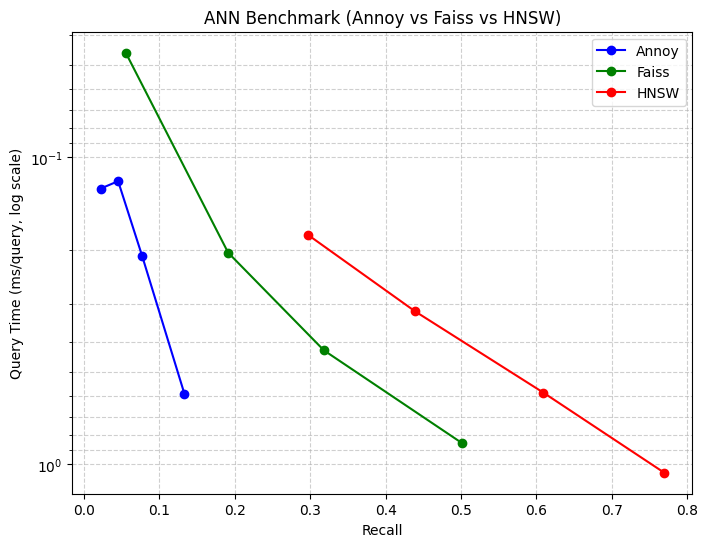

In [7]:
plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()